# SNR for nearby galaxies


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py

from snr_average import average_snr, redshift_to_luminosity_distance

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True

galaxies_bhs_df = pd.read_csv("galaxies_bhs_with_coordinates.csv")

with h5py.File("snr_galaxies.h5", "r") as f:
    m2_grid = f["m2_grid"][:]
    tpl_grid = f["tpl_grid"][:]

    # Read results for all galaxies
    snr_grids = {}
    freq_grids = {}

    for label in f["galaxies"]:
        snr_grids[label] = f[f"galaxies/{label}/snr_grid"][:]
        freq_grids[label] = f[
            f"galaxies/{label}/f_gw_initial_grid"
        ][:]

# Sort galaxies by average SNR, highest first
sorted_labels = sorted(
    snr_grids,
    key=lambda label: np.nanmean(snr_grids[label]),
    reverse=True,
)

# Reorder both dictionaries consistently
snr_grids = {label: snr_grids[label] for label in sorted_labels}
freq_grids = {label: freq_grids[label] for label in sorted_labels}

Fixed tpl value: 21.85482735232525


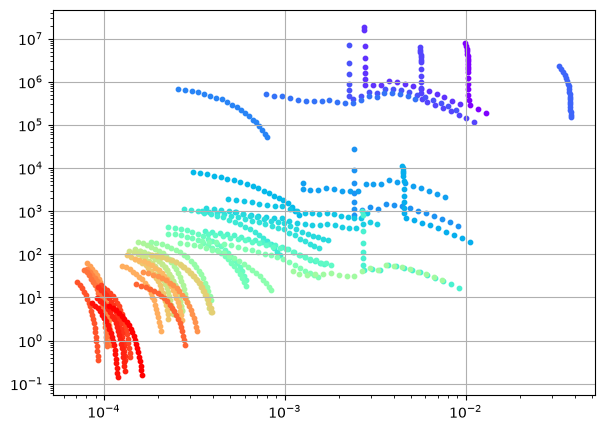

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))

tpl_fixed = tpl_grid[3]
print(f"Fixed tpl value: {tpl_fixed}")

labels = list(snr_grids.keys())
cmap = plt.colormaps["rainbow"]
colors = cmap(np.linspace(0, 1, len(labels)))


for (label, snr_grid), freq_grid, color in zip(snr_grids.items(), freq_grids.values(), colors):
    snr = snr_grid[:,tpl_grid == tpl_fixed]
    freq = freq_grid[:,tpl_grid == tpl_fixed]

    ax.scatter(freq, snr, label=label, color=color, s=10)
    ax.set_xscale("log")
    ax.set_yscale("log")

#ax.legend()
plt.show()


In [2]:
from pathlib import Path
from matplotlib.colors import LogNorm

# Create output folder if it doesn't exist
output_dir = Path("plots")
output_dir.mkdir(parents=True, exist_ok=True)

for label, snr_grid in snr_grids.items():

    # Ignore invalid values when determining the colour scale
    valid_snrs = snr_grid[np.isfinite(snr_grid) & (snr_grid > 0)]

    if len(valid_snrs) == 0:
        print(f"Skipping {label}: no positive, finite SNR values.")
        continue

    fig, ax = plt.subplots(figsize=(7, 5))

    mesh = ax.pcolormesh(
        tpl_grid,
        m2_grid,
        snr_grid,
        shading="auto",
        cmap="viridis",
        norm=LogNorm(vmin=np.nanmin(snr_grid), vmax=np.nanmax(snr_grid)),
    )


    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Time to Plunge", fontsize=14)
    ax.set_ylabel("Secondary mass", fontsize=14)
    ax.set_title(label, fontsize=16)

    # Grid lines on major ticks
    ax.grid(True, which="major", color="0.7", linewidth=1.2)
    ax.set_axisbelow(False)

    cbar = fig.colorbar(mesh, ax=ax)
    cbar.set_label("SNR", fontsize=14)

    plt.tight_layout()

    # Make a filesystem-safe filename
    safe_label = "".join(
        c if c.isalnum() or c in "-_." else "_"
        for c in str(label)
    )
    output_file = output_dir / f"snr_{safe_label}.png"

    fig.savefig(output_file, dpi=200, bbox_inches="tight")
    plt.close(fig)

    print(f"Saved: {output_file}")


Saved: plots/snr_47_Tucanae.png
Skipping Ark 120: no positive, finite SNR values.
Saved: plots/snr_Circinus.png
Skipping Fairall 9: no positive, finite SNR values.
Saved: plots/snr_G1__Mayall_II_.png
Saved: plots/snr_HLX-1__ESO_243-49_.png
Saved: plots/snr_IMBH_100Mpc.png
Saved: plots/snr_IRS_13E.png
Saved: plots/snr_M15__NGC_7078_.png
Saved: plots/snr_M32.png
Saved: plots/snr_M54__NGC_6715_.png
Saved: plots/snr_Milky_Way.png
Saved: plots/snr_Mrk_110.png
Saved: plots/snr_Mrk_202.png
Saved: plots/snr_Mrk_335.png
Saved: plots/snr_Mrk_50.png
Saved: plots/snr_NGC_1023.png
Saved: plots/snr_NGC_1068.png
Saved: plots/snr_NGC_1313_X-1.png
Saved: plots/snr_NGC_1566.png
Saved: plots/snr_NGC_1672.png
Saved: plots/snr_NGC_2787.png
Saved: plots/snr_NGC_3227.png
Saved: plots/snr_NGC_3384.png
Saved: plots/snr_NGC_3489.png
Saved: plots/snr_NGC_3516.png
Saved: plots/snr_NGC_3627.png
Saved: plots/snr_NGC_3783.png
Saved: plots/snr_NGC_3945.png
Saved: plots/snr_NGC_404.png
Saved: plots/snr_NGC_4051.png
Sa

## Limitations (important)

1) In this pipeline, initial conditions are obtained by integrating from near separatrix and then integrating backward for a requested plunge time (`get_initial_conditions` in `snr_average.py`). For very large $T_{\mathrm{pl}}$ and/or large secondary masses, this can fail or become numerically unreliable because the backward integration goes only up to regions where FEW/flux are computed.

2) The SNR can suddenly drop if the source is out of band

3) The `num_freq` controls how many frequency points the computation is using, sometimes is good to check that this is not affecting the results